<a href="https://colab.research.google.com/github/AnnaPaula07/RedeNeuralStackOverflow/blob/main/RedeNeuralStackOverflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import confusion_matrix, f1_score, mean_squared_error

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Utilizando dispositivo: {device}')

Utilizando dispositivo: cpu


In [ ]:
class MeuDataset(Dataset):

  def __init__(self, X, y):
    self.X = torch.tensor(X, dtype=torch.float32)
    self.y = torch.tensor(y, dtype=torch.float32)

  def __len__(self):
    return len(self.X)

  def __getitem__(self, idx):
    return self.X[idx], self.y[idx]

In [ ]:
df = pd.read_csv('survey_results_public.csv')
print("Formato original:", df.shape)

df = df[df["AISelect"].notna()].copy()
df["target"] = df["AISelect"].str.startswith("Yes").astype(int)
print("Formato após remover nulos:", df.shape)

features = [
    'Age',
    'EdLevel',
    'Employment',
    'WorkExp',
    'YearsCode',
    'DevType',
    'AISent',
    'AIThreat'
]
target = 'AISelect'

df = df[features + [target]].dropna(subset=[target])
print("Formato após remover colunas:", df.shape)

X = df[features].copy()
y = df[target].copy()

y = y.apply(lambda value: 0 if value.startswith("No") else 1)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

categorical_features = [
    'Age', 'EdLevel', 'Employment', 'DevType', 'AISent', 'AIThreat'
]
numerical_features = [
    'WorkExp', 'YearsCode'
]
categorical_imputer = SimpleImputer(strategy='most_frequent')
numerical_imputer = SimpleImputer(strategy='mean')

X_train[categorical_features] = categorical_imputer.fit_transform(X_train[categorical_features])
X_val[categorical_features] = categorical_imputer.transform(X_val[categorical_features])
X_test[categorical_features] = categorical_imputer.transform(X_test[categorical_features])

X_train[numerical_features] = numerical_imputer.fit_transform(X_train[numerical_features])
X_val[numerical_features] = numerical_imputer.transform(X_val[numerical_features])
X_test[numerical_features] = numerical_imputer.transform(X_test[numerical_features])

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_cat = encoder.fit_transform(X_train[categorical_features])
X_val_cat = encoder.transform(X_val[categorical_features])
X_test_cat = encoder.transform(X_test[categorical_features])

scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train[numerical_features])
X_val_num = scaler.transform(X_val[numerical_features])
X_test_num = scaler.transform(X_test[numerical_features])

X_train = np.hstack([X_train_cat, X_train_num]).astype(np.float32)
X_val = np.hstack([X_val_cat, X_val_num]).astype(np.float32)
X_test = np.hstack([X_test_cat, X_test_num]).astype(np.float32)

y_train = y_train.to_numpy(dtype=np.int64)
y_val = y_val.to_numpy(dtype=np.int64)
y_test = y_test.to_numpy(dtype=np.int64)

print("Treino:", X_train.shape, y_train.shape)
print("Validação:", X_val.shape, y_val.shape)
print("Teste:", X_test.shape, y_test.shape)
print("Classes:", np.unique(y_train))

print("Quantidade de entradas:", X_train.shape[1])

/tmp/ipykernel_1357/409396082.py:1: DtypeWarning: Columns (56,74,92,97,98,105,109,110,132,162,165) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('survey_results_public.csv')


Formato original: (49191, 172)
Formato após remover nulos: (33720, 173)
Formato após remover colunas: (33720, 9)
Treino: (23604, 64) (23604,)
Validação: (5058, 64) (5058,)
Teste: (5058, 64) (5058,)
Classes: [0 1]
Quantidade de entradas: 64


In [ ]:
train_dataset = MeuDataset(X_train, y_train)
val_dataset = MeuDataset(X_val, y_val)
test_dataset = MeuDataset(X_test, y_test)

batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [49]:
class RedeNeuralStackOverflow(nn.Module):

  def __init__(self, input_dim, output_dim):
    super(RedeNeuralStackOverflow, self).__init__()

    self.camada1 = nn.Linear(input_dim, 64)
    self.ativacao = nn.LeakyReLU(negative_slope=0.01)
    self.dropout = nn.Dropout(0.3)

    self.camada2 = nn.Linear(64, 32)
    self.ativacao = nn.LeakyReLU(negative_slope=0.01)
    self.dropout = nn.Dropout(0.3)

    self.camada_saida = nn.Linear(32, output_dim)

  def forward(self, x):
    x = self.camada1(x)
    x = self.ativacao(x)
    x = self.dropout(x)
    x = self.camada2(x)
    x = self.ativacao(x)
    x = self.dropout(x)
    x = self.camada_saida(x)

    return x

input_size = 64
output_size = 1
model = RedeNeuralStackOverflow(input_size, output_size).to(device)

In [51]:
criterion = nn.BCEWithLogitsLoss()

learning_rate = 0.001

optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)

In [52]:
num_epochs = 50
train_losses = []
val_losses = []

best_val_loss = float('inf')
patience = 10
patience_counter = 0

for epoch in range(num_epochs):

  model.train()
  running_loss = 0.0

  for inputs, targets in train_loader:
    inputs = inputs.to(device)
    targets = targets.to(device)

    optimizer.zero_grad()
    outputs = model(inputs)
    targets = targets.view_as(outputs)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()
    running_loss += loss.item()

  model.eval()
  val_running_loss = 0.0

  with torch.no_grad():
    for inputs, targets in val_loader:
      inputs = inputs.to(device)
      targets = targets.to(device)

      outputs = model(inputs)

      targets = targets.view_as(outputs)

      loss = criterion(outputs, targets)
      val_running_loss += loss.item()

  epoch_train_loss = running_loss / len(train_loader)
  epoch_val_loss = val_running_loss / len(val_loader)

  train_losses.append(epoch_train_loss)
  val_losses.append(epoch_val_loss)

  print(f"Época [{epoch+1}/{num_epochs}] | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

  if epoch_val_loss < best_val_loss:
    best_val_loss = epoch_val_loss
    patience_counter = 0
    torch.save(model.state_dict(), 'best_model.pth')
  else:
    patience_counter += 1
    if patience_counter >= patience:
      print(f"Early stopping! Melhor perda de validação: {best_val_loss:.4f}")
      break

  model.load_state_dict(
    torch.load('best_model.pth', map_location=device)
)
print(f"Melhor Val Loss: {best_val_loss:.4f}")

Época [1/50] | Train Loss: 0.3803 | Val Loss: 0.3218
Época [2/50] | Train Loss: 0.3426 | Val Loss: 0.3201
Época [3/50] | Train Loss: 0.3390 | Val Loss: 0.3229
Época [4/50] | Train Loss: 0.3402 | Val Loss: 0.3200
Época [5/50] | Train Loss: 0.3394 | Val Loss: 0.3208
Época [6/50] | Train Loss: 0.3380 | Val Loss: 0.3214
Época [7/50] | Train Loss: 0.3377 | Val Loss: 0.3228
Época [8/50] | Train Loss: 0.3386 | Val Loss: 0.3212
Época [9/50] | Train Loss: 0.3380 | Val Loss: 0.3254
Época [10/50] | Train Loss: 0.3380 | Val Loss: 0.3211
Época [11/50] | Train Loss: 0.3380 | Val Loss: 0.3224
Época [12/50] | Train Loss: 0.3379 | Val Loss: 0.3210
Época [13/50] | Train Loss: 0.3385 | Val Loss: 0.3220
Época [14/50] | Train Loss: 0.3381 | Val Loss: 0.3251
Early stopping! Melhor perda de validação: 0.3200
Melhor Val Loss: 0.3200


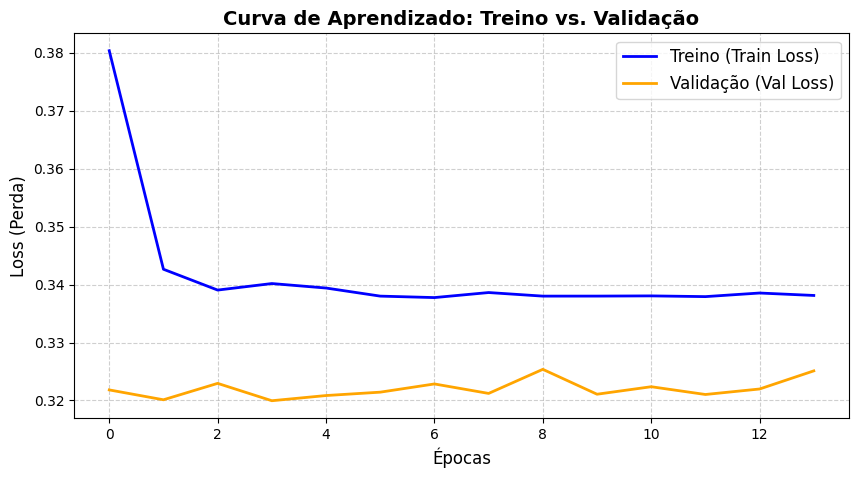

In [53]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Treino (Train Loss)', color='blue', linewidth=2)
plt.plot(val_losses, label='Validação (Val Loss)', color='orange', linewidth=2)

plt.xlabel('Épocas', fontsize=12)
plt.ylabel('Loss (Perda)', fontsize=12)
plt.title('Curva de Aprendizado: Treino vs. Validação', fontsize=14, fontweight='bold')
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()